# Poster Plots for NAWEA
by Lexie Goldberger

This script generates the plots used in my 2024 NAWEA poster, and was run on Amazon Web Services.

## 1. Import Libraries

In [1]:
import os
import datetime
from datetime import datetime
from datetime import timedelta
import numpy as np
import matplotlib
import matplotlib.pyplot as plt
plt.rcParams.update({'font.size': 22})
import matplotlib.patches as mpatches
from matplotlib.collections import LineCollection
from matplotlib.colors import ListedColormap, BoundaryNorm
import matplotlib.colors as colors
from matplotlib.colors import LinearSegmentedColormap
import matplotlib.cbook as cbook
import netCDF4
import xarray as xr
import pandas as pd
import glob
from typing import List
%matplotlib inline
from mpl_toolkits.axes_grid1 import make_axes_locatable
import warnings
warnings.simplefilter('ignore')
from pathlib import Path
import seaborn as sns
import math
from scipy.optimize import curve_fit
import dask.array as da

# Data has been generated, skip to step 5

## 2. Locate Data

In [2]:
# # # Disdrometer Data
# sat_folder = Path("/data/share/goldberger/sat.ld/")
# sa1_z02_folder = Path("/data/share/goldberger/sa1.ld.z02/")
# sh_z02_folder = Path("/data/share/goldberger/sh.ld.z02/")

# # # Surface Met Station data
# sa1_met_folder = Path("/data/share/goldberger/sa1.met.z02/")
# sh_met_folder = Path("/data/share/goldberger/sh.met.z01/")

# # Turbine Data
# basepath_turbine = "/data/share/goldberger/Turbine_data/"

## 3. Import Data

### 3a. Function for opening SCADA Data

In [3]:
# # from each turbine, get the full time series of a chosen variable
# def openturbinedata(basepath_turbine,variable):
#     # 1. Load in every station's data, get just the wattage
#     # Initialize an empty list to store the modified DataArrays
#     modified_data_arrays = []

#     number_strings = [f'{i:03d}' for i in range(1, 89)]
#     for i,x in enumerate(number_strings):
#         file = glob.glob(basepath_turbine + 'wt' + x + '.nc')
#         ds = xr.open_dataset(file[0])
#         new_var_name = ds.attrs['Alias']
#         # Create a mask based on the condition
#         mask = ds['Flag'] == 'Routine'
#         # Use the mask to filter the data
#         filtered_ds = ds.where(mask)
#         #da = filtered_ds['WTUR.W_10m_Avg']
#         try:
#             da = filtered_ds[variable]
#         except KeyError:
#             print(variable + " was passed, whish isn't a variable in the dataset")
#         da = da.rename(new_var_name)
#         # Append the modified DataArray to the list
#         modified_data_arrays.append(da)
#         ds.close()

#     # 2. Combine the individual stations together and get the mean
#     # Trying with dataframes
#     df = modified_data_arrays[0].to_dataframe()
#     number_strings = [f'{i:03d}' for i in range(1, 89)]
#     for i,x in enumerate(number_strings):
#         df[modified_data_arrays[i].name] = modified_data_arrays[i].to_dataframe()
#     df

#     df['mean'] = df.mean(axis=1)
#     # df.index = df.index + pd.to_timedelta(6, unit='h')

#     # 3. Seperate out stations by their letter identifier, to make data more manageable 
#     A = [col for col in df.columns if col.startswith('A')]
#     B = [col for col in df.columns if col.startswith('B')]
#     C = [col for col in df.columns if col.startswith('C')]
#     D = [col for col in df.columns if col.startswith('D')]
#     E = [col for col in df.columns if col.startswith('E')]
#     F = [col for col in df.columns if col.startswith('F')]
#     G = [col for col in df.columns if col.startswith('G')]
#     H = [col for col in df.columns if col.startswith('H')]
#     I = [col for col in df.columns if col.startswith('I')]
#     J = [col for col in df.columns if col.startswith('J')]
#     Colus = [A,B,C,D,E,F,G,H,I,J]
#     return df, Colus;


# Coli = ['A','B','C','D','E','F','G','H','I','J']

# # How to use:
# # [DAT, Colus] = openturbinedata(DAT_directory, variable to plot, eg 'WTUR.W_10m_Avg')

In [4]:
# # Get turbine data

# variable_name =  'WMET.HorWdDir_10m_Avg'
# variable_name_a =  'WYAW.YwAng_10m_Avg'
# [df, Colus] = openturbinedata(basepath_turbine, variable_name)
# [dfa, Colus] = openturbinedata(basepath_turbine, variable_name_a)
# df_wind = dfa['H08'] + df['H08']

# turbine_wind = xr.DataArray(df_wind)
# turbine_wind = turbine_wind.rename({"WTUR.DateTime": "time"})

In [5]:
# # Grab all the data for each site and instrument

# year = '2023'

# ds_SA1 = xr.concat([xr.open_mfdataset(sa1_z02_folder.glob(year + '06' + '*.nc')), 
#                     xr.open_mfdataset(sa1_z02_folder.glob(year + '07' + '*.nc')), 
#                     xr.open_mfdataset(sa1_z02_folder.glob(year + '08' + '*.nc')), 
#                     xr.open_mfdataset(sa1_z02_folder.glob(year + '09' + '*.nc'))], dim = 'time')

# ds_SH = xr.concat([xr.open_mfdataset(sh_z02_folder.glob(year + '06' + '*.nc')), 
#                     xr.open_mfdataset(sh_z02_folder.glob(year + '07' + '*.nc')), 
#                     xr.open_mfdataset(sh_z02_folder.glob(year + '08' + '*.nc')), 
#                     xr.open_mfdataset(sh_z02_folder.glob(year + '09' + '*.nc'))], dim = 'time')

# ds_ST = xr.concat([xr.open_mfdataset(sat_folder.glob(year + '06' + '*.nc')), 
#                     xr.open_mfdataset(sat_folder.glob(year + '07' + '*.nc')), 
#                     xr.open_mfdataset(sat_folder.glob(year + '08' + '*.nc')), 
#                     xr.open_mfdataset(sat_folder.glob(year + '09' + '*.nc'))], dim = 'time')

# met_SA1 = xr.concat([xr.open_mfdataset(sa1_met_folder.glob(year + '06' + '*.nc')), 
#                     xr.open_mfdataset(sa1_met_folder.glob(year + '07' + '*.nc')), 
#                     xr.open_mfdataset(sa1_met_folder.glob(year + '08' + '*.nc')), 
#                     xr.open_mfdataset(sa1_met_folder.glob(year + '09' + '*.nc'))], dim = 'time')

# met_SH = xr.concat([xr.open_mfdataset(sh_met_folder.glob(year + '06' + '*.nc')), 
#                     xr.open_mfdataset(sh_met_folder.glob(year + '07' + '*.nc')), 
#                     xr.open_mfdataset(sh_met_folder.glob(year + '08' + '*.nc')), 
#                     xr.open_mfdataset(sh_met_folder.glob(year + '09' + '*.nc'))], dim = 'time')

In [7]:
# ## Interpolate so their time axes are the same

# # Interpolating the met dataset to match the time coordinates of ds
# ST_met_interp = turbine_wind.interp(time=ds_ST.time)

# # Interpolating the met dataset to match the time coordinates of ds
# SA1_met_interp = met_SA1.interp(time=ds_SA1.time)

# # Interpolating the met dataset to match the time coordinates of ds
# SH_met_interp = met_SH.interp(time=ds_SH.time)

# ## Merge instruments met and ds datasets

# # Combine
# ST_combined = xr.merge([ST_met_interp, ds_ST])
# SA1_combined = xr.merge([SA1_met_interp, ds_SA1])
# SH_combined = xr.merge([SH_met_interp, ds_SH])


## 4. Filter Data
- When rain threshold is met
- When winds are from the south
- Also remove dates 07/01 and 07/02


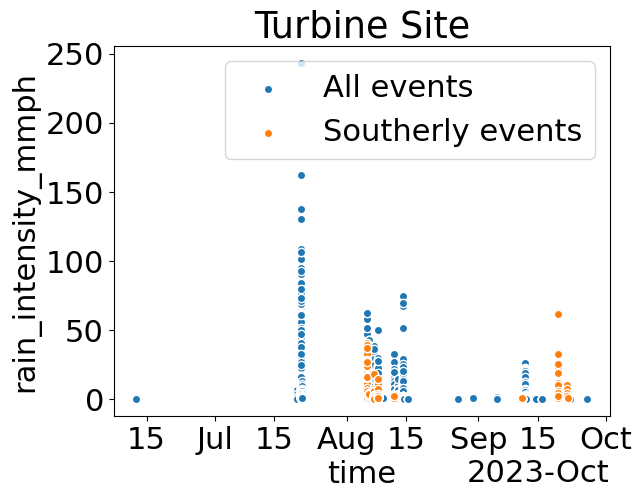

In [8]:
# # Turbine Site

# # Ensure the condition is a DataArray
# condition = ST_combined.rain_intensity_mmph > .1

# # Extract the time coordinate and create a mask for July 1-2
# mask_july_1_2 = np.logical_or(
#     SH_combined.time.dt.strftime('%m-%d') == '07-01',
#     SH_combined.time.dt.strftime('%m-%d') == '07-02'
# )

# # Combine the conditions, making sure that the condition for July 1-2 is False
# condition = da.compute(condition & (~mask_july_1_2))[0] # Assuming 'cond' is a tuple, take the first element

# # Apply the condition using xarray's where method
# ST_filtered = ST_combined.where(condition, drop=True)

# # T Site, only when winds are southerly

# # Assuming combined_filtered['WindDir'] is a Dask array
# cond = (ST_filtered['H08'] > 150) & (ST_filtered['H08'] < 210)

# # Compute the boolean array
# cond = da.compute(cond)[0]  # Assuming 'cond' is a tuple, take the first element

# # Now use .where() with the computed boolean array
# ST_southerly = ST_filtered.where(cond, drop=True)

# # Plot the filtered data
# ST_filtered.rain_intensity_mmph.plot.scatter(label = 'All events')
# ST_southerly.rain_intensity_mmph.plot.scatter(label = 'Southerly events')

# plt.title('Turbine Site')
# plt.legend()



Text(0.5, 1.0, 'A1 Site')

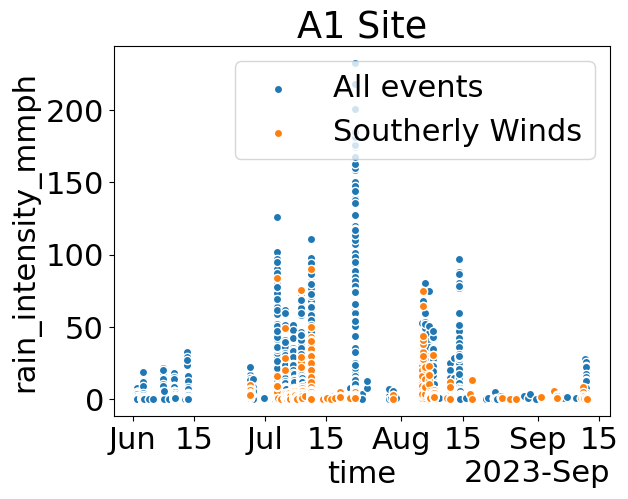

In [9]:
# # A1 Site

# # Ensure the condition is a DataArray
# condition = SA1_combined.rain_intensity_mmph > .1

# # Extract the time coordinate and create a mask for July 1-2
# mask_july_1_2 = np.logical_or(
#     SH_combined.time.dt.strftime('%m-%d') == '07-01',
#     SH_combined.time.dt.strftime('%m-%d') == '07-02'
# )

# # Combine the conditions, making sure that the condition for July 1-2 is False
# condition = da.compute(condition & (~mask_july_1_2))[0] # Assuming 'cond' is a tuple, take the first element

# # Apply the condition using xarray's where method
# SA1_filtered = SA1_combined.where(condition, drop=True)

# # A1 Site, only when winds are southerly

# # Assuming combined_filtered['WindDir'] is a Dask array
# cond = (SA1_filtered['WindDir'] > 160) & (SA1_filtered['WindDir'] < 200)

# # Compute the boolean array
# cond = da.compute(cond)[0]  # Assuming 'cond' is a tuple, take the first element

# # Now use .where() with the computed boolean array
# SA1_southerly = SA1_filtered.where(cond, drop=True)

# # Plot the filtered data
# SA1_filtered.rain_intensity_mmph.plot.scatter(label = 'All events')
# SA1_southerly.rain_intensity_mmph.plot.scatter(label = 'Southerly Winds')
# plt.legend()
# plt.title('A1 Site')

Text(0.5, 1.0, 'H Site')

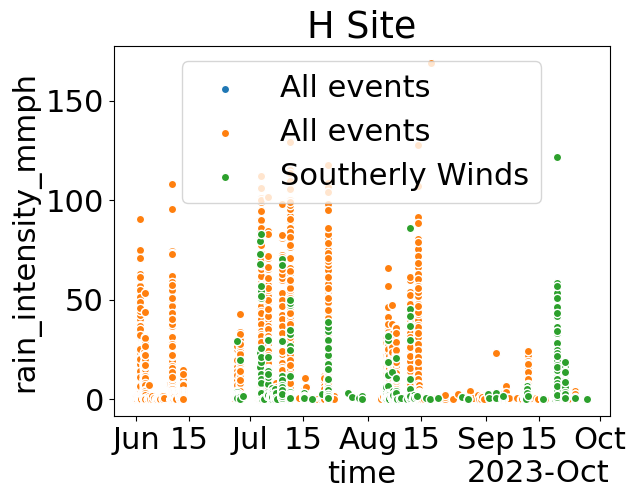

In [10]:
# # H Site

# # Ensure the condition is a DataArray
# condition = SH_combined.rain_intensity_mmph > .1

# # Extract the time coordinate and create a mask for July 1-2
# mask_july_1_2 = np.logical_or(
#     SH_combined.time.dt.strftime('%m-%d') == '07-01',
#     SH_combined.time.dt.strftime('%m-%d') == '07-02'
# )

# # Combine the conditions, making sure that the condition for July 1-2 is False
# condition = da.compute(condition & (~mask_july_1_2))[0] # Assuming 'cond' is a tuple, take the first element

# # Apply the condition using xarray's where method
# SH_filtered = SH_combined.where(condition, drop=True)

# # H Site, only when winds are southerly

# # Assuming combined_filtered['WindDir'] is a Dask array
# cond = (SH_filtered['WindDir'] > 160) & (SH_filtered['WindDir'] < 200)

# # Compute the boolean array
# cond = da.compute(cond)[0]  # Assuming 'cond' is a tuple, take the first element

# # Now use .where() with the computed boolean array
# SH_southerly = SH_filtered.where(cond, drop=True)

# # Plot the filtered data
# SH_filtered.rain_intensity_mmph.plot.scatter(label = 'All events')
# SH_southerly.rain_intensity_mmph.plot.scatter(label = 'Southerly Winds')
# plt.legend()
# plt.title('H Site')

In [ ]:
## 5. Save Data Arrays

In [22]:
# ST_filtered.to_netcdf("ST_filtered.nc")
# ST_southerly.to_netcdf("ST_southerly.nc")
# SA1_filtered.to_netcdf("SA1_filtered.nc")
# SA1_southerly.to_netcdf("SA1_southerly.nc")
# SH_filtered.to_netcdf("SH_filtered.nc")
# SH_southerly.to_netcdf("SH_southerly.nc")

In [202]:
ST_filtered = xr.open_dataset("ST_filtered.nc")
ST_southerly = xr.open_dataset("ST_southerly.nc")
SA1_filtered = xr.open_dataset("SA1_filtered.nc")
SA1_southerly = xr.open_dataset("SA1_southerly.nc")
SH_filtered = xr.open_dataset("SH_filtered.nc")
SH_southerly = xr.open_dataset("SH_southerly.nc")

# Plot: Precip Timeseries

(array([19539., 19553., 19570., 19584., 19601., 19615., 19631.]),
 [Text(19539.0, 0, 'Jul'),
  Text(19553.0, 0, '15'),
  Text(19570.0, 0, 'Aug'),
  Text(19584.0, 0, '15'),
  Text(19601.0, 0, 'Sep'),
  Text(19615.0, 0, '15'),
  Text(19631.0, 0, 'Oct')])

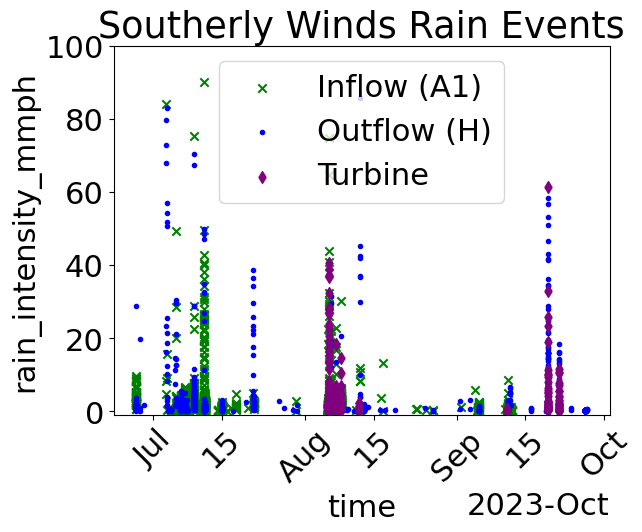

In [204]:
SA1_southerly.rain_intensity_mmph.plot.scatter(label = 'Inflow (A1)', marker = 'x', color = 'green')
SH_southerly.rain_intensity_mmph.plot.scatter(label = 'Outflow (H)', marker = '.', color = 'blue')
ST_southerly.rain_intensity_mmph.plot.scatter(label = 'Turbine', marker = 'd', color = 'purple')
plt.title('Southerly Winds Rain Events')
plt.legend()

# start_date = pd.to_datetime('2023-08-12 03:05:00')
# end_date = pd.to_datetime('2023-08-12 03:35:00')
# start_date = pd.to_datetime('2023-07-11 09:00:00')
# end_date = pd.to_datetime('2023-07-11 12:35:00')
#plt.xlim([start_date, end_date])
plt.ylim([-1,100])
plt.xticks(rotation=45)

# Plot: Bar chart of NWS Weather Types

In [12]:
# Process data to get each precipitaiton category for every month and calculate its percentage of the time it happened that month

# Get dates
years = ['2023']
months = [f"{num:02d}" for num in range(6, 10)]
year_month_combinations = [year + month for year in years for month in months]
index=pd.to_datetime(year_month_combinations, format='%Y%m')

# Get Stations
columns=['Inflow','Turbine', 'Outflow']
variables = [SA1_southerly['NWS_weather_code'],ST_southerly['NWS_weather_code'], SH_southerly['NWS_weather_code']]

# Get Weather Codes
NWS_codes = ['A', 'C',
            'L ', 'L-',
            'R', 'R+', 'R-', 
            'RL ','RL+', 'RL-', 
            'RLS', 'RLS-',
            'S', 'S+', 'S-', 
            'SP']


# Create MultiIndex
multi_index = pd.MultiIndex.from_product([index, NWS_codes], names=['Index1', 'Index2'])

# Make the dataframe            
df_p = pd.DataFrame(index=multi_index, columns=columns)

for index, station in enumerate(columns):
    variable = variables[index]
    print(station)
    for date_combo in year_month_combinations:
        print(date_combo)
        time_range = slice(date_combo[0:4] + '-' + date_combo[4:6] + '-01',date_combo[0:4] + '-' + str(int(date_combo[4:6]) + 1) + '-01')
        # open the dataset
        try:
            ds = variable.sel(time=time_range)

            # Convert xarray DataArray to numpy array
            data_array = ds.values

            # Get unique strings and their counts
            unique_strings, counts = np.unique(data_array, return_counts=True)
            print(unique_strings)
            print(counts)

        except OSError:
            #print(f'no data in {date_combo} for station {station}')
            pass
        

Inflow
202306
['A' 'R' 'R+' 'R-' 'SP']
[ 1 26  6 11  3]
202307
['A' 'R' 'R+' 'R-' 'RL-' 'SP']
[  5 158  51 611   8  14]
202308
['A' 'R' 'R+' 'R-' 'SP']
[ 20  97  21 209   2]
202309
['R' 'R+' 'R-' 'RL-' 'SP']
[  3   1 204  12   1]
Turbine
202306
[]
[]
202307
[]
[]
202308
['A' 'R' 'R+' 'R-' 'RL-' 'SP']
[  7  30  20 126   1  11]
202309
['A' 'R' 'R+' 'R-' 'RL-' 'SP']
[ 4 15 11 53  1  2]
Outflow
202306
['A' 'R' 'R+' 'R-']
[ 2  3  1 62]
202307
['A' 'R' 'R+' 'R-' 'SP']
[ 13  98  42 461   7]
202308
['A' 'R' 'R+' 'R-' 'RL-' 'SP']
[ 10  19   9 222   5   3]
202309
['A' 'L ' 'L-' 'R' 'R+' 'R-' 'RL-' 'SP']
[ 35  13 162  51  40 299  81   4]


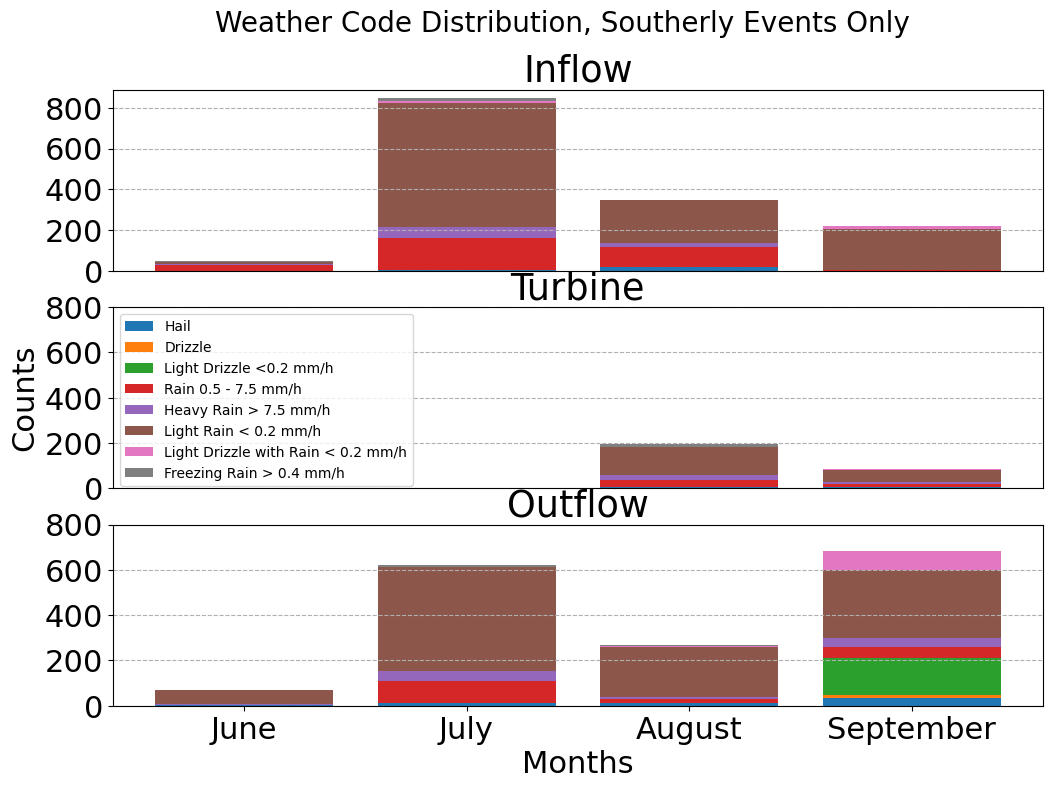

In [57]:
# Order: 'A', 'L', 'L-', 'R', 'R+', 'R-', 'RL-', 'SP'

data = {
    'Inflow': {
        'June': ([1, 0, 0, 26, 6, 11, 0, 3]),
        'July': ([5, 0, 0, 158, 51, 611, 8, 14]),
        'August': ([20, 0, 0, 97, 21, 209, 0, 2]),
        'September': ([0, 0, 0, 3, 1, 204, 12, 1]),
    },
    'Turbine': {
        'June': ([0, 0, 0, 0, 0, 0, 0, 0]),
        'July': ([0, 0, 0, 0, 0, 0, 0, 0]),
        'August': ([7, 0, 0, 30, 20, 126, 1, 11]),
        'September': ([4, 0, 0, 15, 11, 53, 1, 2]),
    },
    'Outflow': {
        'June': ([2, 0, 0, 3, 1, 62, 0, 0]),
        'July': ([13, 0, 0, 98, 42, 461, 0, 7]),
        'August': ([10, 0, 0, 19, 9, 222, 5, 3]),
        'September': ([35, 13, 162, 51, 40, 299, 81, 4]),
    }
}    

fig, axs = plt.subplots(3, 1, figsize=(12, 8))

# Create the stacked bar plot
sales_data = data['Inflow']
products = list(sales_data.keys())
sales = np.array(list(sales_data.values()))
axs[0].bar(products, sales[:, 0], label='Hail')  # A
axs[0].bar(products, sales[:, 1], bottom=sales[:, 0], label='Drizzle') #L  
axs[0].bar(products, sales[:, 2], bottom=sales[:, 0] + sales[:, 1], label='Light Drizzle <0.2 mm/h') # L-
axs[0].bar(products, sales[:, 3], bottom=sales[:, 0] + sales[:, 1] + sales[:, 2], label='Rain 0.5 - 7.5 mm/h')  
axs[0].bar(products, sales[:, 4], bottom=sales[:, 0] + sales[:, 1] + sales[:, 2] + sales[:, 3], label='Heavy Rain > 7.5 mm/h')  
axs[0].bar(products, sales[:, 5], bottom=sales[:, 0] + sales[:, 1] + sales[:, 2] + sales[:, 3] + sales[:, 4], label='Light Rain < 0.2 mm/h') 
axs[0].bar(products, sales[:, 6], bottom=sales[:, 0] + sales[:, 1] + sales[:, 2] + sales[:, 3] + sales[:, 4] + sales[:, 5], label='Light Drizzle with Rain < 0.2 mm/h') 
axs[0].bar(products, sales[:, 7], bottom=sales[:, 0] + sales[:, 1] + sales[:, 2] + sales[:, 3] + sales[:, 4] + sales[:, 5] + sales[:, 6], label='Freezing Rain > 0.4 mm/h')  

# Create the stacked bar plot
sales_data = data['Turbine']
products = list(sales_data.keys())
sales = np.array(list(sales_data.values()))
axs[1].bar(products, sales[:, 0], label='Hail')  # A
axs[1].bar(products, sales[:, 1], bottom=sales[:, 0], label='Drizzle') #L  
axs[1].bar(products, sales[:, 2], bottom=sales[:, 0] + sales[:, 1], label='Light Drizzle <0.2 mm/h') # L-
axs[1].bar(products, sales[:, 3], bottom=sales[:, 0] + sales[:, 1] + sales[:, 2], label='Rain 0.5 - 7.5 mm/h')  
axs[1].bar(products, sales[:, 4], bottom=sales[:, 0] + sales[:, 1] + sales[:, 2] + sales[:, 3], label='Heavy Rain > 7.5 mm/h')  
axs[1].bar(products, sales[:, 5], bottom=sales[:, 0] + sales[:, 1] + sales[:, 2] + sales[:, 3] + sales[:, 4], label='Light Rain < 0.2 mm/h') 
axs[1].bar(products, sales[:, 6], bottom=sales[:, 0] + sales[:, 1] + sales[:, 2] + sales[:, 3] + sales[:, 4] + sales[:, 5], label='Light Drizzle with Rain < 0.2 mm/h') 
axs[1].bar(products, sales[:, 7], bottom=sales[:, 0] + sales[:, 1] + sales[:, 2] + sales[:, 3] + sales[:, 4] + sales[:, 5] + sales[:, 6], label='Freezing Rain > 0.4 mm/h')  

# Create the stacked bar plot
sales_data = data['Outflow']
products = list(sales_data.keys())
sales = np.array(list(sales_data.values()))
axs[2].bar(products, sales[:, 0], label='Hail')  # A
axs[2].bar(products, sales[:, 1], bottom=sales[:, 0], label='Drizzle') #L  
axs[2].bar(products, sales[:, 2], bottom=sales[:, 0] + sales[:, 1], label='Light Drizzle <0.2 mm/h') # L-
axs[2].bar(products, sales[:, 3], bottom=sales[:, 0] + sales[:, 1] + sales[:, 2], label='Rain 0.5 - 7.5 mm/h')  
axs[2].bar(products, sales[:, 4], bottom=sales[:, 0] + sales[:, 1] + sales[:, 2] + sales[:, 3], label='Heavy Rain > 7.5 mm/h')  
axs[2].bar(products, sales[:, 5], bottom=sales[:, 0] + sales[:, 1] + sales[:, 2] + sales[:, 3] + sales[:, 4], label='Light Rain < 0.2 mm/h') 
axs[2].bar(products, sales[:, 6], bottom=sales[:, 0] + sales[:, 1] + sales[:, 2] + sales[:, 3] + sales[:, 4] + sales[:, 5], label='Light Drizzle with Rain < 0.2 mm/h') 
axs[2].bar(products, sales[:, 7], bottom=sales[:, 0] + sales[:, 1] + sales[:, 2] + sales[:, 3] + sales[:, 4] + sales[:, 5] + sales[:, 6], label='Freezing Rain > 0.4 mm/h')  

# Customize the plot
axs[0].grid(axis='y', linestyle='--');axs[1].grid(axis='y', linestyle='--');axs[2].grid(axis='y', linestyle='--')
axs[0].set_yticks([0, 200,400,600,800]);
axs[1].set_yticks([0, 200,400,600,800]);
axs[2].set_yticks([0, 200,400,600,800]);
axs[0].set_xticks([])
axs[1].set_xticks([])
axs[0].set_title('Inflow');axs[1].set_title('Turbine');axs[2].set_title('Outflow')
axs[2].set_xlabel('Months')
axs[1].set_ylabel('Counts')
axs[1].legend(fontsize=10)
# axs[2].tick_params(axis='x', rotation=45)
plt.suptitle('Weather Code Distribution, Southerly Events Only', fontsize =20)
# Show the plot
plt.show()


## 6. Filter out Hail and Freezing Rain
'A', 'SP'


In [23]:
# INFLOW

# Ensure the condition is a DataArray
condition1 = SA1_southerly['NWS_weather_code'] != 'A'
condition2 = SA1_southerly['NWS_weather_code'] != 'SP'

# Combine the conditions
condition = da.compute(condition1 & condition2)[0] 

# Apply the condition using xarray's where method
SA1_southerly = SA1_southerly.where(condition, drop=True)

# TURBINE

# Ensure the condition is a DataArray
condition1 = ST_southerly['NWS_weather_code'] != 'A'
condition2 = ST_southerly['NWS_weather_code'] != 'SP'

# Combine the conditions
condition = da.compute(condition1 & condition2)[0] 

# Apply the condition using xarray's where method
ST_southerly = ST_southerly.where(condition, drop=True)

# OUTFLOW

# Ensure the condition is a DataArray
condition1 = SH_southerly['NWS_weather_code'] != 'A'
condition2 = SH_southerly['NWS_weather_code'] != 'SP'

# Combine the conditions
condition = da.compute(condition1 & condition2)[0] 

# Apply the condition using xarray's where method
SH_southerly = SH_southerly.where(condition, drop=True)

# Plot: Total number vs volume of droplets

In [28]:
xdata = ST_filtered.diameter_ve.values

ST_sum =            ST_filtered['Dve_bin_concentration'].sel(time=ST_filtered.time.dt.month == 8).mean(dim='time')/xdata
ST_sum_southerly =  ST_southerly['Dve_bin_concentration'].sel(time=ST_southerly.time.dt.month == 8).mean(dim='time')/xdata
SA1_sum =           SA1_filtered['Dve_bin_concentration'].sel(time=SA1_filtered.time.dt.month == 8).mean(dim='time')/xdata
SA1_sum_southerly = SA1_southerly['Dve_bin_concentration'].sel(time=SA1_southerly.time.dt.month == 8).mean(dim='time')/xdata
SH_sum =            SH_filtered['Dve_bin_concentration'].sel(time=SH_filtered.time.dt.month == 8).mean(dim='time')/xdata
SH_sum_southerly =  SH_southerly['Dve_bin_concentration'].sel(time=SH_southerly.time.dt.month == 8).mean(dim='time')/xdata


In [29]:
# Get Data

ST_total = ST_sum_southerly.values
SA1_total = SA1_sum_southerly.values
SH_total = SH_sum_southerly.values

ST_total_all = ST_sum.values
SA1_total_all = SA1_sum.values
SH_total_all = SH_sum.values


# Calculate the mass of water
# 1. get the volume assuming its a sphere
# 2. use the density of water to get the mass
diameter = xdata
rho = 1000 # kg/m3, density of water
mass_pd = rho *(4/3)* np.pi * (diameter*0.001/2)**3 # mass per droplet for each bin
mass_H = mass_pd * SH_total
mass_A1 = mass_pd * SA1_total
mass_T = mass_pd * ST_total

mass_H_all = mass_pd * SH_total_all
mass_A1_all = mass_pd * SA1_total_all
mass_T_all = mass_pd * ST_total_all

<BarContainer object of 6 artists>

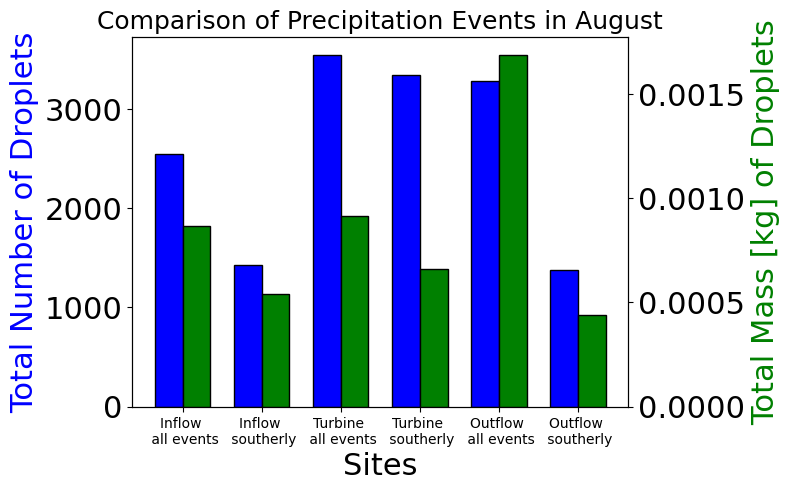

In [30]:
fig, ax = plt.subplots()
ax2 = ax.twinx()

categories = ['Inflow \n all events', 'Inflow \n southerly', 'Turbine \n all events', 'Turbine \n southerly', 'Outflow \n all events','Outflow \n southerly']
values_left = [SA1_total_all.sum(), SA1_total.sum(), ST_total_all.sum(), ST_total.sum(), SH_total_all.sum(),SH_total.sum()]
values_right = [mass_A1_all.sum(), mass_A1.sum(), mass_T_all.sum(),mass_T.sum(), mass_H_all.sum(),mass_H.sum()]

# Calculate the positions of the bars
bar_width = 0.35
index = np.arange(len(categories))

ax.set_title('Comparison of Precipitation Events in August', fontsize = 18)
ax.set_xlabel('Sites')
ax.set_ylabel('Total Number of Droplets', color='blue')
ax2.set_ylabel('Total Mass [kg] of Droplets', color='green')

ax.set_xticks(index)
ax.set_xticklabels(categories, fontsize = 10)



ax.bar(index - bar_width/2, values_left, bar_width, color='blue', edgecolor='black', label = 'Number')
ax2.bar(index + bar_width/2, values_right, bar_width, color='green', edgecolor='black', label = 'Mass')

# Plot Droplet Size Distributions

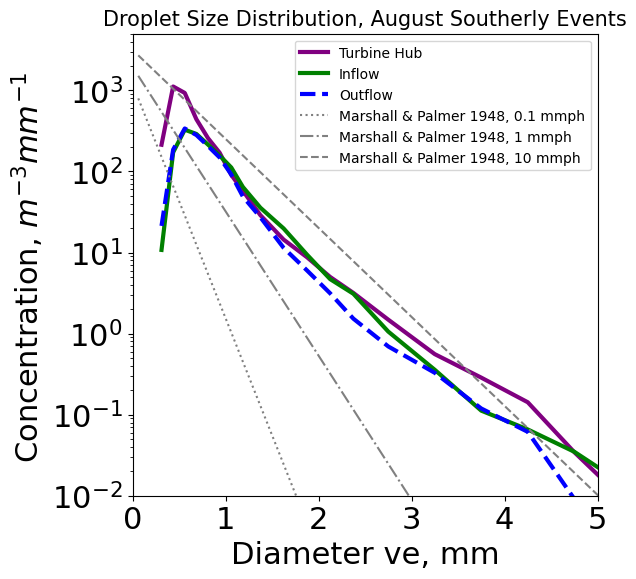

In [81]:
xdata = ST_sum.diameter_ve.values

N = 1000*np.exp(-1*2.6*xdata)
N2 = 1000*np.exp(-1*1.6*xdata)
# $ 1E3 * e^{-[1.6 - 2.6]*D} $
N3 = (16000000/(8200*0.1**(-1*0.21)))*np.exp(-1*(8200*0.1**(-1*0.21))*xdata*0.0005)
N4 = (16000000/(8200*1**(-1*0.21)))*np.exp(-1*(8200*1**(-1*0.21))*xdata*0.0005)
N5 = (16000000/(8200*10**(-1*0.21)))*np.exp(-1*(8200*10**(-1*0.21))*xdata*0.0005)
fig, ax = plt.subplots(figsize=(6,6))

ax.plot(xdata,ST_sum_southerly.where(ST_sum_southerly > 0), label = 'Turbine Hub', color = 'purple',linewidth=3)
ax.plot(xdata,SA1_sum_southerly.where(SA1_sum_southerly > 0), label = 'Inflow', color = 'green',linewidth=3)
ax.plot(xdata, SH_sum_southerly.where(SH_sum_southerly > 0), label = 'Outflow', color = 'blue',linewidth=3, linestyle = 'dashed')
# ax.plot(xdata[2:21], N[2:21], label = 'Straka 2000, $ \lambda $ = 2.6', color = 'black', linestyle = '--')
# ax.plot(xdata[2:21], N2[2:21],  color = 'black', linestyle = '-.', label = 'Straka 2000 $ \lambda $ = 1.6')
ax.plot(xdata[0:21], N3[0:21],  color = 'grey', linestyle = 'dotted', label = 'Marshall & Palmer 1948, 0.1 mmph')
ax.plot(xdata[0:21], N4[0:21],  color = 'grey', linestyle = '-.', label = 'Marshall & Palmer 1948, 1 mmph')
ax.plot(xdata[0:21], N5[0:21],  color = 'grey', linestyle = '--', label = 'Marshall & Palmer 1948, 10 mmph')
plt.xlabel('Diameter ve, mm')
plt.ylabel('Concentration, $ m^{-3} mm^{-1} $ ')
plt.title('Droplet Size Distribution, August Southerly Events', fontsize = 15)
# plt.xscale('log')
plt.xlim([0, 5])
plt.ylim([.01, 5000])
plt.yscale('log')
plt.legend(fontsize = 10)
plt.show()

In [35]:
## Seperate by Rain Rate
# Light is < 0.3
# Mod is 0.5-7.5
# Strong is >7.5

## Site H
# low intensity is <5, high is >25
cond = (SH_southerly['rain_intensity_mmph'] < .3)
cond = da.compute(cond)[0] 
SH_southerly_low = SH_southerly.where(cond, drop=True)
#
cond = (SH_southerly['rain_intensity_mmph'] > 7.5)
cond = da.compute(cond)[0] 
SH_southerly_high = SH_southerly.where(cond, drop=True)

## Site A1
# low intensity is <5, high is >25
cond = (SA1_southerly['rain_intensity_mmph'] < .3)
cond = da.compute(cond)[0] 
SA1_southerly_low = SA1_southerly.where(cond, drop=True)
#
cond = (SA1_southerly['rain_intensity_mmph'] > 7.5)
cond = da.compute(cond)[0] 
SA1_southerly_high = SA1_southerly.where(cond, drop=True)

## Turbine ST_filtered
# low intensity is <5, high is >25
cond = (ST_southerly['rain_intensity_mmph'] < .3)
cond = da.compute(cond)[0] 
ST_southerly_low = ST_southerly.where(cond, drop=True)
#
cond = (ST_southerly['rain_intensity_mmph'] > 7.5)
cond = da.compute(cond)[0] 
ST_southerly_high = ST_southerly.where(cond, drop=True)


In [36]:
# Sum droplet size to get its distribution

ST_sum_southerly_low =   ST_southerly_low['Dve_bin_concentration'].mean(dim='time')/xdata
ST_sum_southerly_high =  ST_southerly_high['Dve_bin_concentration'].mean(dim='time')/xdata
SA1_sum_southerly_low =  SA1_southerly_low['Dve_bin_concentration'].mean(dim='time')/xdata
SA1_sum_southerly_high = SA1_southerly_high['Dve_bin_concentration'].mean(dim='time')/xdata
SH_sum_southerly_low =   SH_southerly_low['Dve_bin_concentration'].mean(dim='time')/xdata
SH_sum_southerly_high =  SH_southerly_high['Dve_bin_concentration'].mean(dim='time')/xdata

In [37]:
def best_func(RR, xdata):
    W = 67*RR**0.846
    V = (4/3)* np.pi * (xdata/2)**3
    k = 2.25
    k1 = k*(xdata)**(k-1)
    k2 = (1.3*RR**0.232)
    k3 = -1*((xdata)/k2)**k
    N = (W/V)*(k1/(k2**k))*np.exp(k3)
    return N



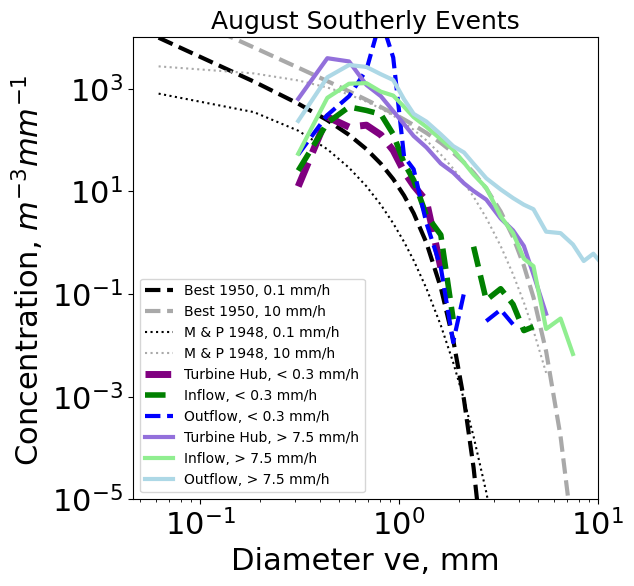

In [105]:
xdata = ST_sum.diameter_ve.values

fig, ax = plt.subplots(figsize=(6,6))
ax.plot(xdata, best_func(0.1, xdata), label = 'Best 1950, 0.1 mm/h', color = 'black', linestyle = '--',linewidth = 3)
ax.plot(xdata, best_func(10, xdata), label = 'Best 1950, 10 mm/h', color = 'darkgrey', linestyle = '--',linewidth = 3)
# ax.plot(xdata, best_func(100, xdata), label = 'Best 1950, 100 mmph', color = 'lightgrey', linestyle = '--',linewidth = 3)

ax.plot(xdata[0:21], N3[0:21],  color = 'black', linestyle = 'dotted', label = 'M & P 1948, 0.1 mm/h')
# ax.plot(xdata[0:21], N4[0:21],  color = 'grey', linestyle = '-.', label = 'M & P 1948, 1 mm/h')
ax.plot(xdata[0:21], N5[0:21],  color = 'darkgrey', linestyle = 'dotted', label = 'M & P 1948, 10 mm/h')

ax.plot(xdata,ST_sum_southerly_low.where(ST_sum_southerly_low > 0), label = 'Turbine Hub, < 0.3 mm/h', color = 'purple',linewidth = 5, linestyle='dashed')
ax.plot(xdata,SA1_sum_southerly_low.where(SA1_sum_southerly_low > 0), label = 'Inflow, < 0.3 mm/h', color = 'green',linewidth = 4, linestyle='dashed')
ax.plot(xdata, SH_sum_southerly_low.where(SH_sum_southerly_low > 0), label = 'Outflow, < 0.3 mm/h', color = 'blue',linewidth = 3, linestyle='dashed')
ax.plot(xdata,ST_sum_southerly_high.where(ST_sum_southerly_high > 0), label = 'Turbine Hub, > 7.5 mm/h', color = '#9370DB',linewidth = 3)
ax.plot(xdata,SA1_sum_southerly_high.where(SA1_sum_southerly_high > 0), label = 'Inflow, > 7.5 mm/h', color = '#90EE90',linewidth = 3)
ax.plot(xdata, SH_sum_southerly_high.where(SH_sum_southerly_high > 0), label = 'Outflow, > 7.5 mm/h', color = '#ADD8E6',linewidth = 3)

# ax.plot(xdata[2:21], N2[2:21],  color = 'black', linestyle = '--')
plt.xlabel('Diameter ve, mm')
plt.ylabel('Concentration, $ m^{-3} mm^{-1} $ ')
plt.title('August Southerly Events', fontsize = 18)
plt.xscale('log')
plt.xlim([0, 10])
plt.ylim([.00001, 10000])
plt.yscale('log')
#plt.legend(fontsize = 10)
plt.legend(fontsize=10)# , loc='upper left', bbox_to_anchor=(.8, 1.1))
plt.show()

# Plot Diameter vs Fall Speed Heat Map

In [83]:
# Sum along the first dimension (time dimension), ignore values < 

ST_s_filtered_sum = ST_southerly['Dve_FS_bin_concentration'].sel(time=ST_southerly.time.dt.month == 8).mean(dim='time')
ST_s_array = ST_s_filtered_sum.where(ST_s_filtered_sum > 0.08)

SA1_s_filtered_sum = SA1_southerly['Dve_FS_bin_concentration'].sel(time=SA1_southerly.time.dt.month == 8).mean(dim='time')
SA1_s_array = SA1_s_filtered_sum.where(SA1_s_filtered_sum > 0.08)

SH_s_filtered_sum = SH_southerly['Dve_FS_bin_concentration'].sel(time=SH_southerly.time.dt.month == 8).mean(dim='time')
SH_s_array = SH_s_filtered_sum.where(SH_s_filtered_sum > 0.08)


In [62]:
# Function for producing data for curve fit

def heat_map_curve(variable,title):

    # Remove shattering data, aka where fall speed less than 1.4 m/s remember I switched the label names with diameter :(
    variable = variable.where(variable.diameter_ve > 1.4)
    
    # Part 1: Generate all (x, y, z) triplets, we need this to generate a curve fit, this takes awhile to run for some reason

    pairs_w = []

    for i in variable.diameter_ve.values:
        for j in variable.fall_Speed_ms.values:
            # print(str(i) + ', ' + str(j))
            z_val = variable.sel(diameter_ve = i, fall_Speed_ms = j)
            if math.isnan(z_val):
                continue
            else:
                pairs_w.append([i,j,int(z_val.values)])

    # Part 2: Turn our 1D x,y,z data into x and y values so that a curve can be fitted

    x_val = []
    y_val = []
    
    for count, value in enumerate(pairs_w):
        for i in range(value[2]):
            x_val.append(value[0])
            y_val.append(value[1])

    # Trying a simple fit




    xdata_w = y_val
    ydata_w = x_val



    # return(popt_w, xdata_w, ydata_w)
    return(xdata_w, ydata_w)

In [85]:
# Get values for beard law calculation

# ST
# Some values calculated
T_T = SA1_southerly['AirT_C_Avg'].sel(time=SA1_southerly.time.dt.month == 8).values.mean() - 1.8 # Lapse rate
P_T = 960
N_T = ST_southerly['num_particles'].sel(time=ST_southerly.time.dt.month == 8).values.mean()
maxinds_T = ST_s_filtered_sum.compute().argmax(dim = ('diameter_ve','fall_Speed_ms'))
max_diameter_T = ST_s_filtered_sum['fall_Speed_ms'].isel(fall_Speed_ms = maxinds_T['fall_Speed_ms']).values
max_fall_speed_T = ST_s_filtered_sum['diameter_ve'].isel(diameter_ve = maxinds_T['diameter_ve']).values

# A1
T_A1 = SA1_southerly['AirT_C_Avg'].sel(time=SA1_southerly.time.dt.month == 8).values.mean()
P_A1 = SA1_southerly['BP_mbar_Avg'].sel(time=SA1_southerly.time.dt.month == 8).values.mean()
N_A1 = SA1_southerly['num_particles'].sel(time=SA1_southerly.time.dt.month == 8).values.mean()
maxinds_A1 = SA1_s_filtered_sum.compute().argmax(dim = ('diameter_ve','fall_Speed_ms'))
max_diameter_A1 = SA1_s_filtered_sum['fall_Speed_ms'].isel(fall_Speed_ms = maxinds_A1['fall_Speed_ms']).values
max_fall_speed_A1 = SA1_s_filtered_sum['diameter_ve'].isel(diameter_ve = maxinds_A1['diameter_ve']).values

# H
T_H = SH_southerly['AirT_C_Avg'].sel(time=SH_southerly.time.dt.month == 8).values.mean()
P_H = SH_southerly['BP_mbar_Avg'].sel(time=SH_southerly.time.dt.month == 8).values.mean()
N_H = SH_southerly['num_particles'].sel(time=SH_southerly.time.dt.month == 8).values.mean()
maxinds_H = SH_s_filtered_sum.compute().argmax(dim = ('diameter_ve','fall_Speed_ms'))
max_diameter_H = SH_s_filtered_sum['fall_Speed_ms'].isel(fall_Speed_ms = maxinds_H['fall_Speed_ms']).values
max_fall_speed_H = SH_s_filtered_sum['diameter_ve'].isel(diameter_ve = maxinds_H['diameter_ve']).values

In [98]:
# Run to calculate Fits, takes a long time to run

# variables = [ST_s_array,SA1_s_array, SH_s_array]
# titles = ['Turbine Southerly Events', 'Inflow Southerly Events', 'Outflow Southerly Events']
# T = [T_T + 273.15,T_A1 + 273.15,T_H + 273.15];P = [P_T,P_A1,P_H]; N = [N_T,N_A1,N_H]; md = [max_diameter_T,max_diameter_A1,max_diameter_H]; 
# mfs = [max_fall_speed_T,max_fall_speed_A1,max_fall_speed_H]

# popt_i = []

# for i in range(len(variables)):
#     print(titles[i])
#     (xdata, ydata) = heat_map_curve(variables[i].where(variables[i].diameter_ve > 1.4), titles[i])

#     def func(x, a, b, c):
#         return a * x**(b) + c

#     popt_w, pcov_w = curve_fit(func, xdata, ydata)

#     plt.figure(figsize=(8, 8))
#     variables[i].plot(cmap='viridis')
#     plt.plot(np.linspace(0.062,6.5), func(np.linspace(0.062,6.5), *popt_w), 'k', label = 'fit: %5.3f * x^%5.3f + %5.3f' % tuple(popt_w))

#     plt.xlabel('Diameter ve')
#     plt.ylabel('Fall Speed ms')
#     plt.title(titles[i])
#     plt.legend(fontsize = 10)
#     plt.xlim([0,7])
#     plt.ylim([0,15])
#     plt.text(4, 10,f'T = {T[i].round(1)} K \n P = {P[i]} mb \n D_m = {md[i]} mm \n Vel_m = {mfs[i]} ms \n Mean Drops Num = {N[i]}',fontsize=8,bbox=dict(facecolor='lightgreen', alpha=0.5))
#     plt.show()  





Outflow August Southerly Events
1.1560432277666874


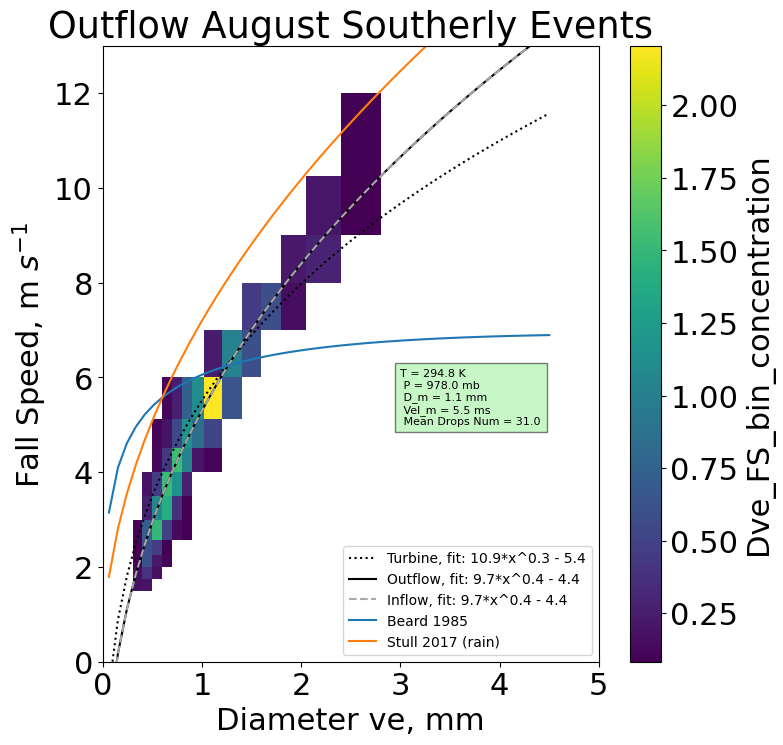

In [99]:
# variables = [ST_s_array,SA1_s_array, SH_s_array]
# titles = ['Turbine Southerly Events', 'Inflow Southerly Events', 'Outflow Southerly Events']
# T = [T_T + 273.15,T_A1 + 273.15,T_H + 273.15];P = [P_T,P_A1,P_H]; N = [N_T,N_A1,N_H]; md = [max_diameter_T,max_diameter_A1,max_diameter_H]; 
# mfs = [max_fall_speed_T,max_fall_speed_A1,max_fall_speed_H]

variables = [SH_s_array.where(SH_s_array.diameter_ve > 1.4)]
titles = ['Outflow August Southerly Events']
T = [T_H + 273.15];P = [P_H]; N = [N_H]; md = [max_diameter_H]; 
mfs = [max_fall_speed_H]

# variables = [SA1_s_array]
# titles = ['Inflow Southerly Events']
# T = [T_A1 + 273.15];P = [P_A1]; N = [N_A1]; md = [max_diameter_A1]; 
# mfs = [max_fall_speed_A1]

for i in range(1):
    print(titles[i])
    plt.figure(figsize=(8, 8))
    variables[i].plot(cmap='viridis')
    x = np.linspace(0.062,4.5)
    plt.plot(x, 10.933*x**0.293 - 5.418, 'k', label = 'Turbine, fit: 10.9*x^0.3 - 5.4', linestyle = 'dotted')
    plt.plot(x, 9.7*x**0.4 - 4.4, 'k', label = 'Outflow, fit: 9.7*x^0.4 - 4.4')
    plt.plot(x, 9.7*x**0.4 - 4.4, color = 'darkgrey', label = 'Inflow, fit: 9.7*x^0.4 - 4.4', linestyle = 'dashed')
   
    # Beard
    density = (P[i]*100/(287.058*T[i])); print(density)
    x = np.log(np.linspace(0.062,4.5))
    Vo = (5.984 + 0.8515*x - 0.1554*x**2 - 0.03274*x**3)
    y = Vo * (1.194 / density) ** (0.375 + 0.025 * x)
    x = np.linspace(0.062,4.5)
    plt.plot(x, y, label = "Beard 1985")
    # Stull 2017
    y = 0.004*220*((density/0.999*density)*((np.linspace(0.062,4.5)*100)/2))**(0.5)
    plt.plot(x, y, label = "Stull 2017 (rain)")
    plt.xlabel('Diameter ve, mm')
    plt.ylabel('Fall Speed, m $ s^{-1} $') 
    plt.title(titles[i])
    plt.legend(fontsize = 10)
    plt.xlim([0,5])
    plt.ylim([0,13])
    plt.text(3, 5,f'T = {T[i].round(1)} K \n P = {P[i].round()} mb \n D_m = {md[i]} mm \n Vel_m = {mfs[i]} ms \n Mean Drops Num = {N[i].round()}',fontsize=8,bbox=dict(facecolor='lightgreen', alpha=0.5))
    plt.show()  





## Get Rain Probabilities for Poster Text

In [209]:
# Convert to pandas Series for easier manipulation
df1 = pd.Series(SA1_southerly.rain_intensity_mmph.time.values)
df2 = pd.Series(SH_southerly.rain_intensity_mmph.time.values)

# Initialize a counter for matches
matches = 0

# Check for each time in data array 1 if there is a corresponding time in data array 2 within an hour
for time in df1:
    if ((df2 >= time) & (df2 <= time + pd.Timedelta(hours=1))).any():
        matches += 1

# Calculate the percentage
percentage_within_hour = (matches / len(df1)) * 100

print(f"Percentage of times at A1 with corresponding precipitation at H within an hour from June to September: {percentage_within_hour:.2f}%")

Percentage of times at A1 with corresponding precipitation at H within an hour from June to September: 75.19%


In [210]:
# Convert to pandas Series for easier manipulation

df1 = pd.Series(SA1_southerly.rain_intensity_mmph.time.values)
df2 = pd.Series(ST_southerly.rain_intensity_mmph.time.values)

# Initialize a counter for matches
matches = 0

# Check for each time in data array 1 if there is a corresponding time in data array 2 within an hour
for time in df1:
    if ((df2 >= time ) & (df2 <= time + pd.Timedelta(hours=1))).any():
        matches += 1

# Calculate the percentage
percentage_within_hour = (matches / len(df1)) * 100

print(f"Percentage of times at A1 with corresponding precipitation at T within an hour: {percentage_within_hour:.2f}%")

Percentage of times at A1 with corresponding precipitation at T within an hour in August: 17.02%


In [211]:
# Convert to pandas Series for easier manipulation
df1 = pd.Series(ST_southerly.rain_intensity_mmph.time.values)
df2 = pd.Series(SH_southerly.rain_intensity_mmph.time.values)

# Initialize a counter for matches
matches = 0

# Check for each time in data array 1 if there is a corresponding time in data array 2 within an hour
for time in df1:
    if ((df2 >= time) & (df2 <= time + pd.Timedelta(hours=1))).any():
        matches += 1

# Calculate the percentage
percentage_within_hour = (matches / len(df1)) * 100

print(f"Percentage of times at T with corresponding precipitation at H within an hour: {percentage_within_hour:.2f}%")

Percentage of times at T with corresponding precipitation at H within an hour in August: 75.09%


# Plot Distribution of Fall Speed

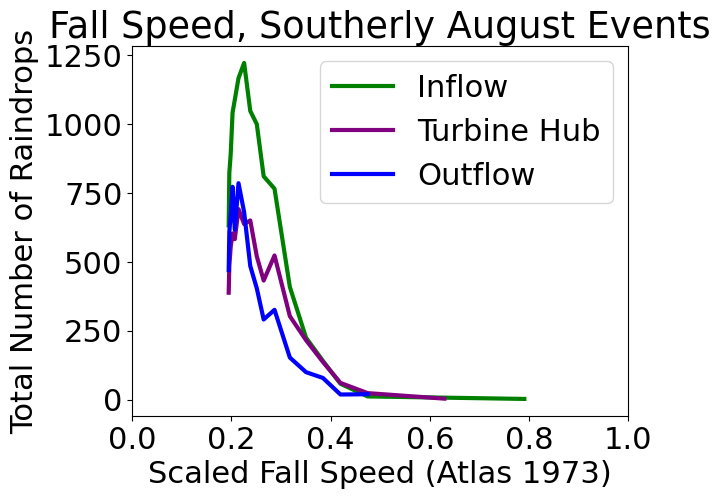

In [185]:
# Scaled Fall Speed
xdata = ST_sum.diameter_ve.values
Vt = (9.65 - 10.3 * np.exp(-1*0.6*xdata))
VfVt = ST_southerly.FS_bin_concentration.fall_Speed_ms.values/Vt # Atlas et al. (1973)


# get values only when raining
ds = SA1_southerly.FS_bin_concentration.sel(time=SA1_southerly.time.dt.month == 8).sum(dim='time')

# Filter the values where ds > 0
mask = ds.values > 0
filtered_VfVt = VfVt[mask]
filtered_ds = ds.values[mask]

# Sort the filtered values
sorted_indices = np.argsort(filtered_VfVt)
sorted_VfVt = filtered_VfVt[sorted_indices]
sorted_ds = filtered_ds[sorted_indices]

# Plot
indices = [0,1,3,4,6,7,8,10,11,12,13,14,15,16,17,18,19]
plt.plot(sorted_VfVt[indices], sorted_ds[indices], label = 'Inflow', color = 'green', linewidth=3)

# get values only when raining
ds = ST_southerly.FS_bin_concentration.sel(time=ST_southerly.time.dt.month == 8).sum(dim='time')

# Filter the values where ds > 0
mask = ds.values > 0
filtered_VfVt = VfVt[mask]
filtered_ds = ds.values[mask]

# Sort the filtered values
sorted_indices = np.argsort(filtered_VfVt)
sorted_VfVt = filtered_VfVt[sorted_indices]
sorted_ds = filtered_ds[sorted_indices]

# Plot
indices = [0,1,3,4,6,7,8,10,11,12,13,14,15,16,17,18,19]
plt.plot(sorted_VfVt[indices], sorted_ds[indices], label = 'Turbine Hub', color = 'purple', linewidth=3)

# get values only when raining
ds = SH_southerly.FS_bin_concentration.sel(time=SH_southerly.time.dt.month == 8).sum(dim='time')

# Filter the values where ds > 0
mask = ds.values > 0
filtered_VfVt = VfVt[mask]
filtered_ds = ds.values[mask]

# Sort the filtered values
sorted_indices = np.argsort(filtered_VfVt)
sorted_VfVt = filtered_VfVt[sorted_indices]
sorted_ds = filtered_ds[sorted_indices]

# Plot
indices = [0,1,3,4,6,7,8,10,11,12,13,14,15,16,17,18]
plt.plot(sorted_VfVt[indices], sorted_ds[indices], label = 'Outflow', color = 'blue', linewidth=3)

plt.xlim([0,1])
plt.xlabel('Scaled Fall Speed (Atlas 1973)')
plt.ylabel('Total Number of Raindrops')
plt.title('Fall Speed, Southerly August Events')
plt.legend()
plt.show()

# Plot Case Study

In [ ]:
# Load in ARM Disdrometer Dataset

SGP_LD = xr.open_dataset("sgpdisdrometerC1.b1.20230805.000000.cdf")

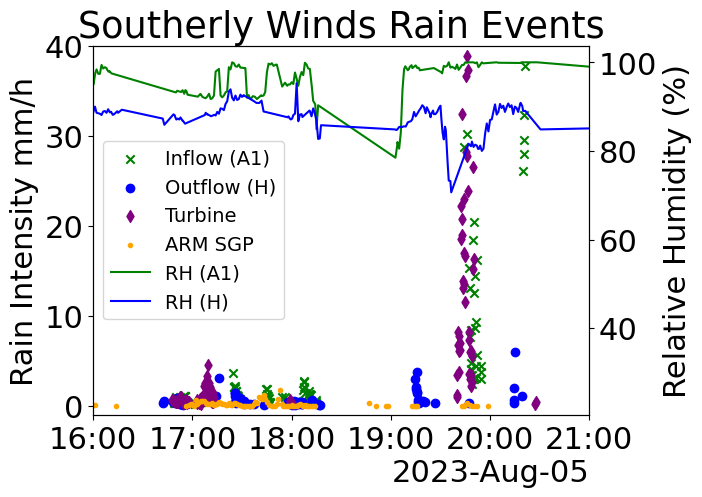

In [218]:
fig, ax1 = plt.subplots()

# Scatter plots for rain intensity
SA1_southerly.rain_intensity_mmph.plot.scatter(ax=ax1, label='Inflow (A1)', marker='x', color='green')
SH_southerly.rain_intensity_mmph.plot.scatter(ax=ax1, label='Outflow (H)', marker='o', color='blue')
ST_southerly.rain_intensity_mmph.plot.scatter(ax=ax1, label='Turbine', marker='d', color='purple')
SGP_LD.rain_rate.sel(time=time_range).where(SGP_LD.rain_rate >0).plot.scatter(ax = ax1, label = 'ARM SGP', marker = '.',color = 'orange')
# Create a second y-axis for the RH lines
ax2 = ax1.twinx()

# Plot the RH lines
SA1_filtered.RH.plot(ax=ax2, label='RH (A1)', color='green')
SH_filtered.RH.plot(ax=ax2, label='RH (H)', color='blue')

# Set titles and labels
plt.title('Southerly Winds Rain Events')
ax1.set_ylabel('Rain Intensity mm/h')
ax2.set_ylabel('Relative Humidity (%)')
ax1.set_xlabel('')

# Set x-axis limits
start_date = pd.to_datetime('2023-08-05 16:00:00')
end_date = pd.to_datetime('2023-08-05 21:00:00')
plt.xlim([start_date, end_date])
ax1.set_ylim([-1, 40])
plt.xticks(rotation=45)

# Combine legends from both axes
lines, labels = ax1.get_legend_handles_labels()
lines2, labels2 = ax2.get_legend_handles_labels()
ax2.legend(lines + lines2, labels + labels2, loc='center left', fontsize = 14)

# Show the plot
plt.show()


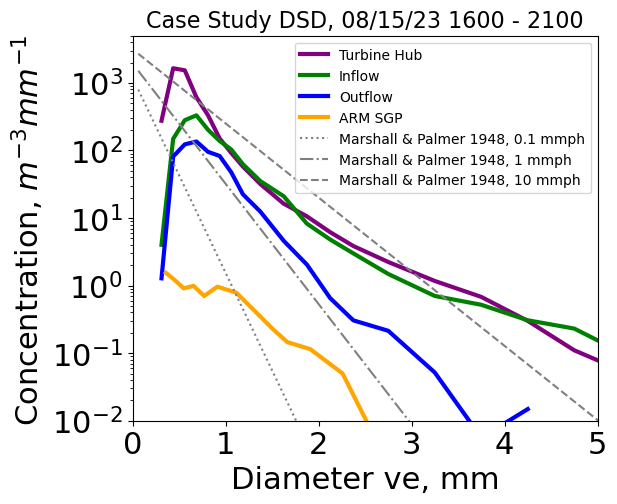

In [225]:
xdata = ST_filtered.diameter_ve.values
time_range = slice('2023-08-05 16:00:00', '2023-08-05 21:00:00')


ST_sum =            ST_filtered['Dve_bin_concentration'].sel(time=time_range).mean(dim='time')/xdata
ST_sum_southerly =  ST_southerly['Dve_bin_concentration'].sel(time=time_range).mean(dim='time')/xdata
SA1_sum =           SA1_filtered['Dve_bin_concentration'].sel(time=time_range).mean(dim='time')/xdata
SA1_sum_southerly = SA1_southerly['Dve_bin_concentration'].sel(time=time_range).mean(dim='time')/xdata
SH_sum =            SH_filtered['Dve_bin_concentration'].sel(time=time_range).mean(dim='time')/xdata
SH_sum_southerly =  SH_southerly['Dve_bin_concentration'].sel(time=time_range).mean(dim='time')/xdata

fig, ax = plt.subplots(figsize=(6,5))

ax.plot(xdata,ST_sum_southerly.where(ST_sum_southerly > 0), label = 'Turbine Hub', color = 'purple',linewidth=3)
ax.plot(xdata,SA1_sum_southerly.where(SA1_sum_southerly > 0), label = 'Inflow', color = 'green',linewidth=3)
ax.plot(xdata, SH_sum_southerly.where(SH_sum_southerly > 0), label = 'Outflow', color = 'blue',linewidth=3)
ARM = SGP_LD['num_drop'].sel(time=time_range).mean(dim='time')/SGP_LD['mean_diam_drop_class'].values

ax.plot(SGP_LD['mean_diam_drop_class'].values, ARM, color = 'orange',linewidth=3, label = 'ARM SGP')
ax.plot(xdata[0:21], N3[0:21],  color = 'grey', linestyle = 'dotted', label = 'Marshall & Palmer 1948, 0.1 mmph')
ax.plot(xdata[0:21], N4[0:21],  color = 'grey', linestyle = '-.', label = 'Marshall & Palmer 1948, 1 mmph')
ax.plot(xdata[0:21], N5[0:21],  color = 'grey', linestyle = '--', label = 'Marshall & Palmer 1948, 10 mmph')
plt.xlabel('Diameter ve, mm')
plt.ylabel('Concentration, $ m^{-3} mm^{-1} $ ')
plt.title('Case Study DSD, 08/15/23 1600 - 2100', fontsize = 16)
# plt.xscale('log')
plt.xlim([0, 5])
plt.ylim([.01, 5000])
plt.yscale('log')
plt.legend(fontsize = 10)
plt.show()

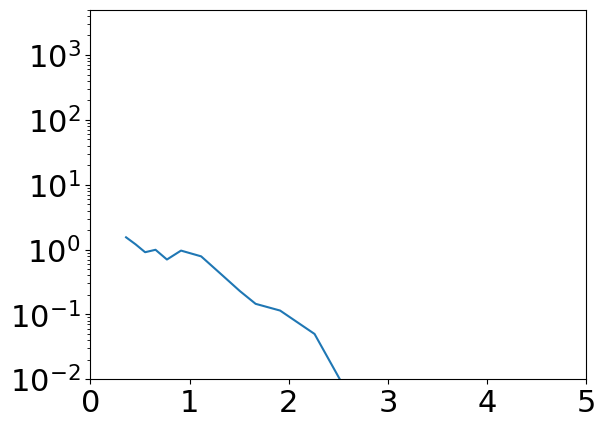

In [221]:
ARM = SGP_LD['num_drop'].sel(time=time_range).mean(dim='time')/SGP_LD['mean_diam_drop_class'].values

plt.plot(SGP_LD['mean_diam_drop_class'].values, ARM, color = 'orange')

plt.xlim([0, 5])
plt.ylim([.01, 5000])
plt.yscale('log')


In [213]:
SGP_LD

<xarray.Dataset>
Dimensions:                 (time: 1440, drop_class: 20)
Coordinates:
  * time                    (time) datetime64[ns] 2023-08-05 ... 2023-08-05T2...
  * drop_class              (drop_class) int32 1 2 3 4 5 6 ... 15 16 17 18 19 20
Data variables: (12/22)
    base_time               datetime64[ns] ...
    time_offset             (time) datetime64[ns] ...
    qc_time                 (time) int32 ...
    mean_diam_drop_class    (drop_class) float32 ...
    fall_velocity           (drop_class) float32 ...
    delta_diam              (drop_class) float32 ...
    ...                      ...
    energy_flux             (time) float32 ...
    distribution_slope      (time) float32 ...
    distribution_intercept  (time) float32 ...
    lat                     float32 ...
    lon                     float32 ...
    alt                     float32 ...
Attributes: (12/25)
    command_line:            disdrometer_ingest -s sgp -f C1
    process_version:         ingest-disdrometer-2.5-1.el7
    dod_version:             disdrometer-b1-1.2
    qc_standards_version:    1.0
    data_level:              b1
    input_source:            /data/collection/sgp/sgpdisdrometerC1.00/SGPCF-2...
    ...                      ...
    qc_bit_2_assessment:     Bad
    qc_bit_3_description:    Value is greater than the valid_max.
    qc_bit_3_assessment:     Bad
    qc_bit_4_description:    Difference between current and previous values e...
    qc_bit_4_assessment:     Indeterminate
    history:                 created by user dsmgr on machine prod-proc4.adc....

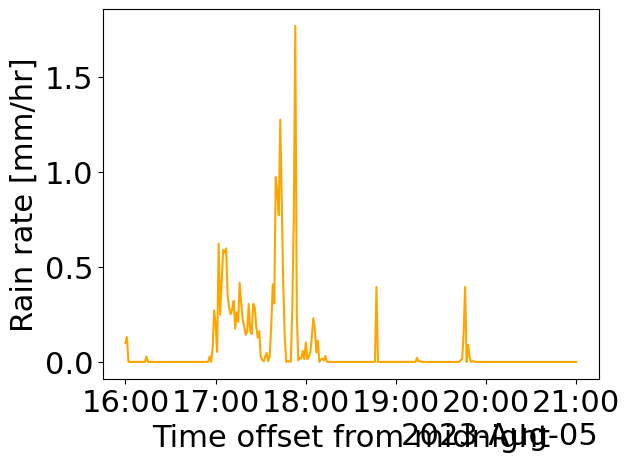

In [215]:
SGP_LD.rain_rate.sel(time=time_range).plot(color = 'orange')